# Naive stream Carving

The approach applies naive stream carving independently on each and every frame. The resultant frames are then stiched together. Temporal information is not considered in this approach.

In [31]:
import cv2
import numpy as np 
from tqdm import tqdm
import matplotlib.pyplot as plt

In [32]:
# Input video
# input_video = "../assets/input/golf.mov"    # (83, 240, 320, 3)
input_video = "../assets/input/ratatouille1.mov"    # (64, 256, 640, 3)

In [33]:
cap = cv2.VideoCapture(input_video)

if not cap.isOpened():
    print(f"Could not open {input_video}")
else: 
    frames = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(frame)

cap.release()

# This will print (T, H, W, C) 
frames = frames[:60]    # Using only first 60 frames
print(f"Video shape: ({len(frames)}, {frames[0].shape[0]}, {frames[0].shape[1]}, {frames[0].shape[2]})")

Video shape: (60, 256, 640, 3)


In [34]:
def backward_energy(img, visualize=False):
    """
    Energy map using sobel filter
    """
    xgrad = cv2.Sobel(img, cv2.CV_32F, dx=1, dy=0, ksize=3, borderType=cv2.BORDER_DEFAULT)
    ygrad = cv2.Sobel(img, cv2.CV_32F, dx=0, dy=1, ksize=3, borderType=cv2.BORDER_DEFAULT)
    back_energy = np.sqrt(np.sum(xgrad**2, axis=2) + np.sum(ygrad**2, axis=2))

    if (visualize):
        # cv2.imwrite("backward_energy.jpg", back_energy)
        plt.imshow(back_energy, cmap="gray")
        plt.show()

    return back_energy

In [35]:
def forward_energy(img, visualize=False):
    """
    Energy map using backward energy and the intensity difference created by removing the pixel
    """

    back_energy = backward_energy(img)

    for_energy = back_energy.copy()

    for i in range(1, img.shape[0]):
        for j in range(img.shape[1]):

            if (j == 0):    # Here, we can only account for top and right
                cU = for_energy[i-1, j]
                cR = for_energy[i-1, j+1] + np.sum(np.abs(img[i, j] - img[i, j+1]))
                min_cost = min(cU, cR)

            elif (j == img.shape[1] - 1):    # Here, we can only account for top and left
                cU = for_energy[i-1, j]
                cL = for_energy[i-1, j-1] + np.sum(np.abs(img[i, j] - img[i, j-1]))
                min_cost = min(cU, cL)

            else:    # Here, we can account for top, right and left
                cU = for_energy[i-1, j]
                cL = for_energy[i-1, j-1] + np.sum(np.abs(img[i, j] - img[i, j-1]))
                cR = for_energy[i-1, j+1] + np.sum(np.abs(img[i, j] - img[i, j+1]))
                min_cost = min(cL, cU, cR)
        
            for_energy[i][j] += min_cost
    
    if (visualize):
        for_energy = cv2.normalize(for_energy, None, 0, 255, cv2.NORM_MINMAX)
        plt.imshow(for_energy, cmap="gray")
        plt.show()

    return for_energy

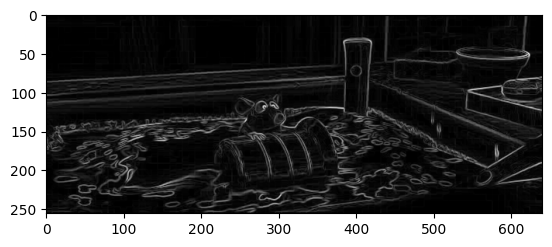

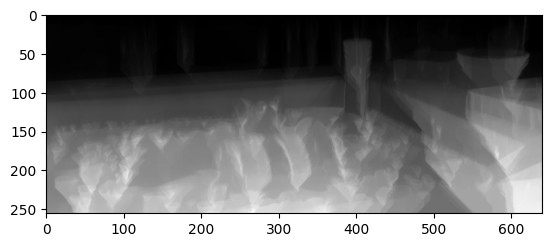

In [36]:
back_energy = backward_energy(frames[0], visualize=True)
for_energy = forward_energy(frames[0], visualize=True)

In [37]:
# forward_energy_maps = []
# backward_energy_maps = []

# for frame in frames:
#     for_energy = forward_energy(frame)
#     back_energy = backward_energy(frame)

#     forward_energy_maps.append(for_energy)
#     backward_energy_maps.append(back_energy)

In [ ]:
def find_vertical_stream(energy, stream_width):

    max_starting_position = energy.shape[1] - stream_width    # For (i, j), we evaluate cost till (i, j+stream_width)

    # Calculating prefix sums for easy computation
    prefix = np.zeros((energy.shape[0], energy.shape[1] + 1), dtype=np.float32)
    prefix[:, 1:] = np.cumsum(energy, axis=1)    # The first column is 0s

    def stream_cost(i, j):
        return prefix[i, j + stream_width] - prefix[i, j]
    
    dp = np.full((energy.shape[0], max_starting_position + 1), np.inf, dtype=np.float32)
    back = np.zeros((energy.shape[0], max_starting_position + 1), dtype=np.int32)

    # The first row remains as it is
    for j in range(max_starting_position + 1):
        dp[0, j] = stream_cost(0, j)

    for i in range(1, energy.shape[0]):
        for j in range(max_starting_position + 1):
            best_prev = dp[i - 1, j]
            best_idx = j

            if j > 0 and dp[i - 1, j - 1] < best_prev:
                best_prev = dp[i - 1, j - 1]
                best_idx = j - 1

            if j < max_starting_position and dp[i - 1, j + 1] < best_prev:
                best_prev = dp[i - 1, j + 1]
                best_idx = j + 1

            dp[i, j] = stream_cost(i, j) + best_prev
            back[i, j] = best_idx

    seams = np.zeros(energy.shape[0], dtype=np.int32)
    j = np.argmin(dp[-1])
    seams[-1] = j

    for i in range(energy.shape[0] - 2, -1, -1):
        j = back[i + 1, j]
        seams[i] = j

    return seams

def find_horizontal_stream(energy, stream_width):
    seams_v = find_vertical_stream(energy.T, stream_width)  
    seams_h = [seam.copy() for seam in seams_v]      
    return seams_h

In [ ]:
def visualize_vertical_stream(img, seam, stream_width):
    visualization_img = img.copy()
    for i in range(len(seam)):
        max_start = img.shape[1] - stream_width
        j_start = min(seam[i], max_start)
        j_end = min(j_start + stream_width, visualization_img.shape[1])
        visualization_img[i, j_start:j_end, :] = (255, 0, 0)  
    return visualization_img


def visualize_horizontal_stream(img, seam, stream_width):
    visualization_img = img.copy()
    for i in range(len(seam)):
        max_start = img.shape[0] - stream_width
        i_start = min(seam[i], max_start)
        i_end = min(i_start + stream_width, visualization_img.shape[0])
        visualization_img[i_start:i_end, i, :] = (0, 0, 255)
    return visualization_img


In [ ]:
def remove_vertical_stream(img, seam_left, stream_width):
    out_img = np.zeros((img.shape[0], img.shape[1] - stream_width, img.shape[2]), dtype=img.dtype)
    for i in range(img.shape[0]):
        j_start = seam_left[i]
        j_end = min(j_start + stream_width, img.shape[1])
        out_img[i, :, :] = np.delete(img[i, :, :], np.s_[j_start:j_end], axis=0)

    return out_img

def remove_horizontal_stream(img, seam_top, stream_width):
    img_T = img.transpose(1, 0, 2)  
    out_T = remove_vertical_stream(img_T, seam_top, stream_width)
    return out_T.transpose(1, 0, 2)  


In [ ]:
def resize(img, target_h, target_w, stream_width, visualize = False):
    modified_img = img.copy()
    num_vertical_seams = img.shape[1] - target_w
    num_horizontal_seams = img.shape[0] - target_h

    if (visualize):
        visualization_frames = []

    while num_vertical_seams > 0 or num_horizontal_seams > 0:
        energy = forward_energy(modified_img)

        # This is to ensure that we cover the residual band if stream_width is large
        vertical_width = min(stream_width, num_vertical_seams)
        horizontal_width = min(stream_width, num_horizontal_seams)

        if vertical_width > 0 and horizontal_width == 0:
            seam = find_vertical_stream(energy, vertical_width)
            if (visualize):
                visualization_img = visualize_vertical_stream(modified_img, seam, vertical_width)
                visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)    # For visualization in form of video
                visualization_frames.append(visualization_resized)
            modified_img = remove_vertical_stream(modified_img, seam, vertical_width)
            num_vertical_seams -= vertical_width
            continue

        if horizontal_width > 0 and vertical_width == 0:
            seam = find_vertical_stream(energy.T, horizontal_width)
            if (visualize):
                visualization_img = visualize_horizontal_stream(modified_img, seam, horizontal_width)
                visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
                visualization_frames.append(visualization_resized)
            modified_img = remove_horizontal_stream(modified_img, seam_top, horizontal_width)
            num_horizontal_seams -= horizontal_width
            continue

        seam_left = find_vertical_stream(energy, vertical_width)
        vertical_cost = sum(energy[i, seam_left[i]:seam_left[i]+vertical_width].sum() for i in range(energy.shape[0]))

        seam_top = find_vertical_stream(energy.T, horizontal_width)
        horizontal_cost = sum(energy.T[j, seam_top[j]:seam_top[j]+horizontal_width].sum() for j in range(energy.shape[1]))

        if vertical_cost <= horizontal_cost:
            if (visualize):
                visualization_img = visualize_vertical_stream(modified_img, seam_left, vertical_width)
                visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
                visualization_frames.append(visualization_resized)
            modified_img = remove_vertical_stream(modified_img, seam_left, vertical_width)
            num_vertical_seams -= vertical_width
        else:
            if (visualize):
                visualization_img = visualize_horizontal_stream(modified_img, seam_top, horizontal_width)
                visualization_resized = cv2.resize(visualization_img, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
                visualization_frames.append(visualization_resized)
            modified_img = remove_horizontal_stream(modified_img, seam_top, horizontal_width)
            num_horizontal_seams -= horizontal_width

    if (visualize):
        return modified_img, visualization_frames
    else:
        return modified_img

(256, 640, 3)


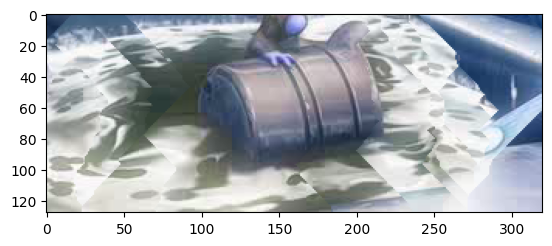

In [42]:
# Testing on one image
print(frames[0].shape)
modified_img, visualization_frames = resize(frames[0], 128, 320, 20, visualize=True)

plt.imshow(modified_img)
plt.show()

In [43]:
def save_video(frames, output_path, fps=30):
    h, w, c = frames[0].shape
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    writer = cv2.VideoWriter(output_path, fourcc, fps, (w, h), isColor=True)

    for f in frames:
        writer.write(f)
    writer.release()
    
    print(f"Saved output video to {output_path}")

In [ ]:
# save_video(visualization_frames, "../assets/output/extras/example_naive_stream_carving_output_golf.mp4", fps=10)
save_video(visualization_frames, "../assets/output/extras/example_naive_stream_carving_output_ratatouille1.mp4", fps=10)

Saved output video to ../assets/output/extras/example_naive_strip_carving_output_ratatouille1.mp4


In [ ]:
# Running naive stream carving for all frames
modified_frames = []
target_h = 128    # 200
target_w = 320    # 200

for frame in tqdm(frames):
    modified_frame = resize(frame, target_h, target_w, 10)
    modified_frames.append(modified_frame)

100%|██████████| 60/60 [07:32<00:00,  7.54s/it]


In [ ]:
# save_video(modified_frames, "../assets/output/naive_stream_carving_output_golf.mp4", fps=30)
save_video(modified_frames, "../assets/output/stream_carving/naive_approach/naive_stream_carving_output_ratatouille1.mp4", fps=30)

Saved output video to ../assets/output/naive_strip_carving_output_ratatouille1_suboptimal_50.mp4
